# LAB 11 — Machine Learning for Time Series Forecasting

**Module:** Machine Learning for Time Series Forecasting
**Session:** 11
**Duration:** 150 minutes (10-minute break included), plus optional Advanced Challenges
**Audience:** LAB02-LAB10'u tamamlamış katılımcılar (başlangıç seviyesi ağırlıklı, az sayıda deneyimli katılımcı)

## LAB10'dan Devam

LAB10'da üç basit baseline (Naive, Seasonal Naive, Moving Average) geliştirip, bunları
Rolling-Origin Evaluation ile karşılaştırdık. LAB11'de bu protokolü **birebir koruyarak**
(aynı split, aynı 4 forecast origin, aynı 14 günlük horizon, aynı MASE denominator), zaman
serisini bir **Supervised Learning** problemine dönüştürüp dört regression modeli (Ridge,
Random Forest, XGBoost, LightGBM) ile **Recursive Multi-Step Forecasting** uygulayacağız.

Bu LAB'ın amacı sadece regression estimator'larını çalıştırmak değildir. Amaç:

1. Lag/Rolling/Calendar feature engineering ile leakage-safe bir supervised veri seti kurmak.
2. Training ve inference (recursive forecasting) sırasında **aynı** feature tanımlarının
   kullanıldığını (Training-Inference Parity) somut olarak doğrulamak.
3. Recursive Forecasting mekanizmasını ve Error Accumulation riskini anlamak.
4. ML modellerini LAB10'un **gerçek** baseline sonuçlarıyla dürüstçe karşılaştırmak -- ML
   modelinin otomatik olarak kazanacağını varsaymadan.
5. LAB12 için somut, gerekçelendirilmiş bir model adayı seçmek.

## Learning Objectives

Bu LAB sonunda katılımcılar:

1. Time Series Forecasting problemini Supervised Learning problemine dönüştürebilecek.
2. Lag Features oluşturabilecek.
3. Rolling Statistics kullanabilecek.
4. Calendar Features geliştirebilecek.
5. Feature Availability kontrolü gerçekleştirebilecek.
6. Temporal Leakage risklerini belirleyebilecek.
7. Direct ve Recursive Forecasting yaklaşımlarının farkını açıklayabilecek.
8. Recursive Multi-Step Forecasting uygulayabilecek.
9. Ridge, Random Forest, XGBoost ve LightGBM regression modellerini forecasting için
   kullanabilecek.
10. Feature engineering ve estimator bileşenlerini tutarlı bir pipeline içinde yönetebilecek.
11. Rolling-Origin Backtesting gerçekleştirebilecek.
12. ML modellerini LAB10 baseline'larıyla karşılaştırabilecek.
13. MAE, RMSE, WAPE, MASE ve Forecast Bias hesaplayabilecek.
14. Horizon-Based Error Analysis gerçekleştirebilecek.
15. Recursive Error Accumulation kavramını açıklayabilecek.
16. Model Complexity ve Forecasting Performance arasındaki ilişkiyi değerlendirebilecek.
17. LAB12 için uygun bir model adayı seçebilecek.

## Dataset & Protokol

LAB10 ile birebir aynı: **Bike Sharing — day.csv**, target `cnt`, forecast horizon **14 gün**,
seasonal period **7 gün**, aynı chronological split (Training 609 / Validation 61 / Protected
Test 61 gün) ve aynı 4 forecast origin (`2012-08-31`, `2012-09-14`, `2012-09-28`, `2012-10-12`).
Bu LAB'da **yeni bir dependency eklenmedi** -- scikit-learn, XGBoost ve LightGBM zaten mevcut.

> **Korunmuş Test Seti:** `2012-11-01` - `2012-12-31` dönemi bu LAB boyunca da **hiçbir analizde
> kullanılmaz**. Bu LAB içinde test seti üzerinde final evaluation **yapılmaz** -- bu LAB12'ye
> bırakılmıştır.


---

## Section 1 — LAB10 Review & ML Forecasting Fundamentals
**Süre: 10 dakika**

### Learning Objective

Baseline forecasting yöntemlerinden Machine Learning tabanlı forecasting yöntemlerine geçişi
anlamak.

### Concept Explanation

Machine Learning regression algoritmaları zaman serisi kavramını doğrudan bilmez -- `Ridge`,
`RandomForestRegressor`, `XGBRegressor`, `LGBMRegressor` hepsi **i.i.d. satırlar** üzerinde
çalışan genel amaçlı regressor'lardır. Zamansal bilgiyi bu modellerin kullanabileceği
feature'lara dönüştürmemiz gerekir -- örneğin:

```text
Date        Lag_1  Lag_7  Rolling_Mean_7  Target
2012-08-01   ...    ...        ...          ...
2012-08-02   ...    ...        ...          ...
2012-08-03   ...    ...        ...          ...
```

Bu yapı, geçmiş gözlemlerden geleceğe ilişkin `target`'ı tahmin etmek için kullanılabilir.

### Mathematical Representation

One-Step Forecast:

$$\hat{y}_t = f(y_{t-1}, y_{t-7}, x_t)$$

Burada `f` regression model, `y_{t-1}` önceki gözlem, `y_{t-7}` 7 günlük lag, `x_t` forecast
tarihi için **bilinen** (calendar) feature'lardır. Bu gösterim yalnızca örnek bir model
specification'dır.

### Critical Question

**"Regression modelini bir günlük (`T+1`) tahmin için eğittik. Peki aynı modelle gelecek 14
günü nasıl tahmin edeceğiz?"**

Bu sorunun yanıtı **Recursive Forecasting**'dir (Section 5) -- modelin kendi ürettiği
tahminleri, bir sonraki adımın lag feature'ları olarak kullanması.

---

## Section 2 — Dataset Recovery & Forecasting Protocol
**Süre: 15 dakika**

### Learning Objective

LAB10'un dataset'ini ve evaluation protokolünü yeniden kullanmak -- varsaymadan, **gerçek
config ve artifact değerlerinden doğrulayarak**.

In [1]:
# Same environment setup pattern as LAB02-LAB10.
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from data_loading import load_config, load_bike_sharing_daily  # noqa: E402

config = load_config()
lab10_cfg = config["lab10"]  # read-only reference -- LAB10 files are never modified
lab11_cfg = config["lab11"]
RANDOM_SEED = config["random_seed"]
print("Project root:", PROJECT_ROOT)
print("lab11 config loaded:", list(lab11_cfg.keys()))

Project root: C:\Users\pc\ml-labs
lab11 config loaded: ['dataset_path', 'target', 'forecasting', 'features', 'models', 'benchmark', 'evaluation', 'artifacts']


### Dataset Reusability & Fingerprinting

Dataset'i tekrar yükleyip, hash'ini LAB10'un gerçek `forecasting_metadata.json` dosyasındaki
değerle karşılaştırıyoruz -- varsaymadan.

In [2]:
import hashlib


def calculate_file_hash(path: Path, chunk_size: int = 8 * 1024 * 1024) -> str:
    hasher = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            hasher.update(chunk)
    return hasher.hexdigest()


dataset_path = PROJECT_ROOT / lab11_cfg["dataset_path"]
current_hash = calculate_file_hash(dataset_path)
print("current dataset_sha256:", current_hash)

import json
lab10_artifacts_dir = PROJECT_ROOT / lab10_cfg["artifacts"]["directory"]
lab10_metadata_path = lab10_artifacts_dir / "forecasting_metadata.json"
lab10_split_metadata_path = lab10_artifacts_dir / "split_metadata.json"

if lab10_metadata_path.exists() and lab10_split_metadata_path.exists():
    with open(lab10_metadata_path, encoding="utf-8") as f:
        lab10_metadata = json.load(f)
    with open(lab10_split_metadata_path, encoding="utf-8") as f:
        lab10_split_metadata = json.load(f)
    hash_match = current_hash == lab10_metadata["dataset_sha256"]
    print("LAB10 artifacts found: True")
    print("dataset hash matches LAB10 artifact:", hash_match)
    if not hash_match:
        print("WARNING: dataset version differs from LAB10 -- benchmark results below "
              "should NOT be directly compared against LAB10's numbers.")
else:
    lab10_metadata = None
    lab10_split_metadata = None
    hash_match = None
    print("LAB10 artifacts found: False -- baseline results will be recomputed from scratch "
          "below, following LAB10's exact protocol (no fabricated numbers will be used).")

current dataset_sha256: a6bcf826782d3c0fbfdcbeead17cd0884185a0dafe8ff10cd48a874ee7ba18be
LAB10 artifacts found: True
dataset hash matches LAB10 artifact: True


### Part A — Dataset Loading & Inspection

In [3]:
df = load_bike_sharing_daily(config)
df["dteday"] = pd.to_datetime(df["dteday"], errors="raise")
df = df.sort_values("dteday").reset_index(drop=True)

TARGET_COLUMN = lab11_cfg["target"]["column"]
daily_series = df.set_index("dteday")[TARGET_COLUMN].sort_index()

print("shape:", df.shape)
print("date range:", daily_series.index.min().date(), "->", daily_series.index.max().date())
print("missing values:", df.isna().sum().sum())
print("duplicate dates:", df["dteday"].duplicated().sum())
print("negative cnt:", (df["cnt"] < 0).sum())

full_range = pd.date_range(daily_series.index.min(), daily_series.index.max(), freq="D")
print("missing calendar dates:", len(set(full_range) - set(daily_series.index)))

shape: (731, 16)
date range: 2011-01-01 -> 2012-12-31
missing values: 0
duplicate dates: 0
negative cnt: 0
missing calendar dates: 0


### Configuration Recovery

LAB10 ve LAB11 arasında kritik değerleri karşılaştırıyoruz -- LAB10'un gerçek
`split_metadata.json`'ı varsa onunla, yoksa LAB10'un `config/settings.yaml`'daki
değerleriyle.

In [4]:
split_cfg = lab10_cfg["split"]  # same source of truth as LAB10 -- never redefined here
FORECAST_HORIZON = lab11_cfg["forecasting"]["horizon"]
SEASONAL_PERIOD = lab11_cfg["forecasting"]["seasonal_period"]
MOVING_AVERAGE_WINDOW = lab10_cfg["forecasting"]["moving_average_window"]

print("Training:  ", split_cfg["training_start"], "->", split_cfg["training_end"])
print("Validation:", split_cfg["validation_start"], "->", split_cfg["validation_end"])
print("Test:      ", split_cfg["test_start"], "->", split_cfg["test_end"], "(PROTECTED)")
print("Forecast horizon:", FORECAST_HORIZON, "| Seasonal period:", SEASONAL_PERIOD)

assert FORECAST_HORIZON == lab10_cfg["forecasting"]["horizon"], "Horizon must match LAB10."
assert SEASONAL_PERIOD == lab10_cfg["forecasting"]["seasonal_period"], "Seasonal period must match LAB10."
print("\nLAB10/LAB11 protocol consistency: OK")

Training:   2011-01-01 -> 2012-08-31
Validation: 2012-09-01 -> 2012-10-31
Test:       2012-11-01 -> 2012-12-31 (PROTECTED)
Forecast horizon: 14 | Seasonal period: 7

LAB10/LAB11 protocol consistency: OK


### Data Isolation

In [5]:
train_series = daily_series.loc[split_cfg["training_start"]:split_cfg["training_end"]]
validation_series = daily_series.loc[split_cfg["validation_start"]:split_cfg["validation_end"]]
test_series = daily_series.loc[split_cfg["test_start"]:split_cfg["test_end"]]

print("Training:  ", len(train_series), "days")
print("Validation:", len(validation_series), "days")
print("Test:      ", len(test_series), "days (PROTECTED -- target values not read below)")

if lab10_split_metadata is not None:
    assert len(train_series) == lab10_split_metadata["training_period"]["n_observations"]
    assert len(validation_series) == lab10_split_metadata["validation_period"]["n_observations"]
    assert len(test_series) == lab10_split_metadata["protected_test_period"]["n_observations"]
    print("\nSplit sizes match LAB10's real split_metadata.json: OK")

Training:   609 days
Validation: 61 days
Test:       61 days (PROTECTED -- target values not read below)

Split sizes match LAB10's real split_metadata.json: OK


### Forecast Origins Recovery

LAB10'un 4 forecast origin'ini, `split_metadata.json`'dan (varsa) veya LAB10'un kendi
`create_rolling_origins` mantığından **yeniden üretiyoruz** -- hardcode etmeden.

In [6]:
backtesting_cfg = lab10_cfg["backtesting"]


def create_rolling_origins(first_origin: pd.Timestamp, step_size: int, number_of_origins: int) -> list:
    return [first_origin + pd.Timedelta(days=step_size * i) for i in range(number_of_origins)]


rolling_origins = create_rolling_origins(
    first_origin=pd.Timestamp("2012-08-31"),
    step_size=backtesting_cfg["step_size"],
    number_of_origins=backtesting_cfg["number_of_origins"],
)
print("Forecast origins:", [o.date() for o in rolling_origins])

if lab10_split_metadata is not None:
    expected_origins = [pd.Timestamp(o) for o in lab10_split_metadata["backtesting"]["origins"]]
    assert rolling_origins == expected_origins, "Forecast origins must match LAB10 exactly."
    print("Origins match LAB10's real split_metadata.json: OK")

Forecast origins: [datetime.date(2012, 8, 31), datetime.date(2012, 9, 14), datetime.date(2012, 9, 28), datetime.date(2012, 10, 12)]
Origins match LAB10's real split_metadata.json: OK


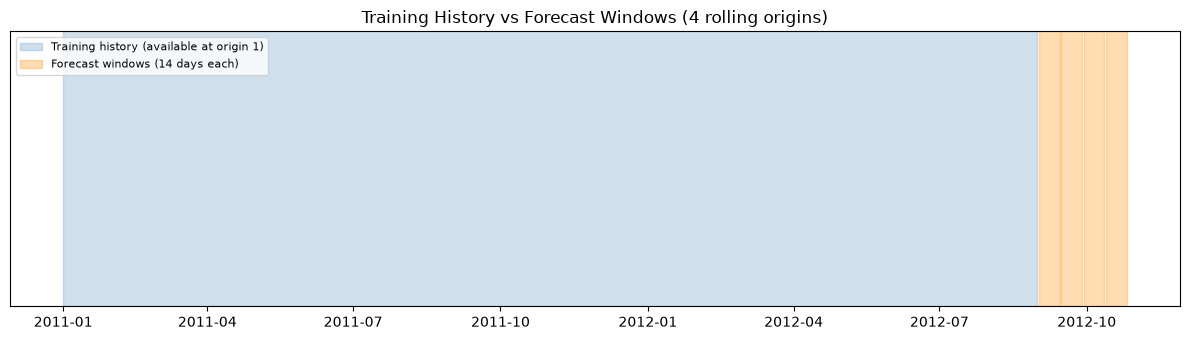

In [7]:
fig, ax = plt.subplots(figsize=(12, 3.5))
_first_origin = rolling_origins[0]
ax.axvspan(train_series.index.min(), _first_origin, color="steelblue", alpha=0.25, label="Training history (available at origin 1)")
for i, origin in enumerate(rolling_origins):
    window_start = origin + pd.Timedelta(days=1)
    window_end = origin + pd.Timedelta(days=FORECAST_HORIZON)
    ax.axvspan(window_start, window_end, color="darkorange", alpha=0.3, label="Forecast windows (14 days each)" if i == 0 else None)
ax.set_title("Training History vs Forecast Windows (4 rolling origins)")
ax.set_yticks([])
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

### Important -- LAB10 Baseline Artifacts

LAB10'un gerçek baseline sonuçları (`baseline_results.csv`) mevcutsa, bunları LAB11'in
benchmark'ında **yeniden hesaplamak yerine doğrudan referans** olarak kullanacağız (aynı
origin/horizon/MASE-denominator protokolüyle, Section 6'da). Eksikse, LAB10'un birebir aynı
fonksiyon mantığıyla burada yeniden üretilecek.

In [8]:
lab10_baseline_path = lab10_artifacts_dir / "baseline_results.csv"
if lab10_baseline_path.exists():
    lab10_baseline_results = pd.read_csv(lab10_baseline_path)
    print("LAB10 baseline_results.csv found:", lab10_baseline_path)
    print(lab10_baseline_results[lab10_baseline_results["Row_Type"] == "AGGREGATE"][
        ["Model", "Aggregation_Method", "MAE", "RMSE", "WAPE", "MASE"]
    ].round(3))
else:
    lab10_baseline_results = None
    print("LAB10 baseline_results.csv NOT found -- will recompute baselines in Section 6 "
          "using LAB10's exact protocol.")

LAB10 baseline_results.csv found: C:\Users\pc\ml-labs\labs\lab10\artifacts\baseline_results.csv
             Model Aggregation_Method      MAE      RMSE    WAPE   MASE
12           Naive          mean_fold  750.232  1066.067  10.591  0.878
13           Naive             pooled  750.232  1105.396  10.545  0.878
14  Seasonal_Naive          mean_fold  894.375  1373.515  12.589  1.047
15  Seasonal_Naive             pooled  894.375  1391.465  12.571  1.047
16  Moving_Average          mean_fold  815.151  1100.902  11.540  0.954
17  Moving_Average             pooled  815.151  1141.373  11.457  0.954


---

## Section 3 — Lag & Rolling Feature Engineering
**Süre: 25 dakika**

Bu LAB'ın ilk kritik mühendislik bölümüdür.

### Learning Objective

Zaman serisi gözlemlerini leakage-safe bir supervised regression formatına dönüştürmek.

### Part A — Lag Features

$$\text{lag}_k(t) = y_{t-k}$$

`lag_1` (önceki gün), `lag_7` (önceki haftanın aynı günü), `lag_14` (iki hafta önce), `lag_28`
(dört hafta önce).

In [9]:
LAGS = lab11_cfg["features"]["lags"]
print("Lags:", LAGS)

# Demonstration on the training series.
lag_demo = pd.DataFrame({"cnt": train_series})
for k in LAGS:
    lag_demo[f"lag_{k}"] = train_series.shift(k)
lag_demo.iloc[25:32]

Lags: [1, 7, 14, 28]


,cnt,lag_1,lag_7,lag_14,lag_28
dteday,,,,,
2011-01-26,506,1985.0,1650.0,1162.0,NaN
2011-01-27,431,506.0,1927.0,1406.0,NaN
2011-01-28,1167,431.0,1543.0,1421.0,NaN
2011-01-29,1098,1167.0,981.0,1248.0,985.0
2011-01-30,1096,1098.0,986.0,1204.0,801.0
2011-01-31,1501,1096.0,1416.0,1000.0,1349.0
2011-02-01,1360,1501.0,1985.0,683.0,1562.0


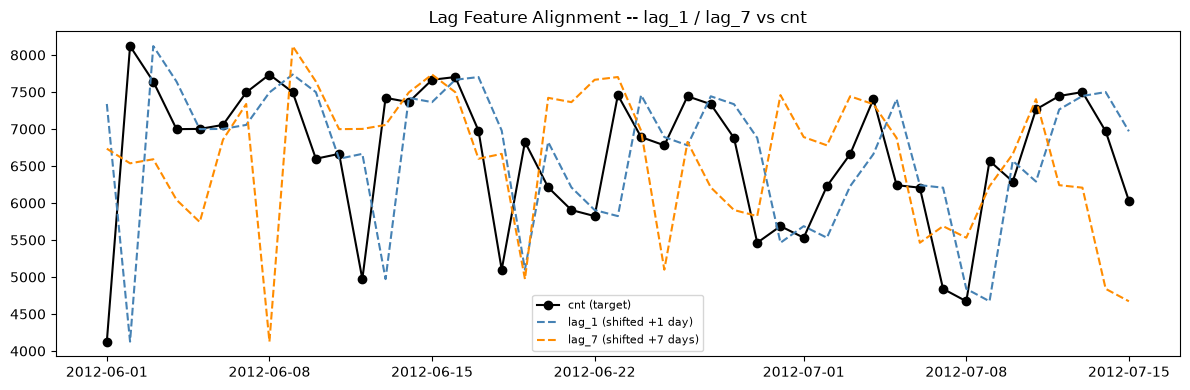

Visually: lag_1 at date d equals cnt at date d-1; lag_7 at date d equals cnt at date d-7.


In [10]:
fig, ax = plt.subplots(figsize=(12, 4))
_window = slice("2012-06-01", "2012-07-15")
ax.plot(lag_demo.loc[_window].index, lag_demo.loc[_window, "cnt"], "o-", color="black", label="cnt (target)")
ax.plot(lag_demo.loc[_window].index, lag_demo.loc[_window, "lag_1"], "--", color="steelblue", label="lag_1 (shifted +1 day)")
ax.plot(lag_demo.loc[_window].index, lag_demo.loc[_window, "lag_7"], "--", color="darkorange", label="lag_7 (shifted +7 days)")
ax.set_title("Lag Feature Alignment -- lag_1 / lag_7 vs cnt")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print("Visually: lag_1 at date d equals cnt at date d-1; lag_7 at date d equals cnt at date d-7.")

### Critical Rule

Bugünün target değeri, bugünün tahminini üretirken feature olarak kullanılmamalıdır --
`shift(0)` (yani `cnt`'in kendisi) asla bir feature değildir, yalnızca `shift(k)` (`k >= 1`)
kullanılır.

### Part B — Rolling Statistics

Önce `shift(1)`, **sonra** `rolling()` uygulanmasının önemi:

**Incorrect (mevcut günün target'ını da içerebilir):**
```python
target.rolling(window=7).mean()
```

**Correct (yalnızca daha önce gerçekleşmiş değerleri kullanır):**
```python
target.shift(1).rolling(window=7).mean()
```

In [11]:
ROLL_MEAN = lab11_cfg["features"]["rolling_mean"]
ROLL_STD = lab11_cfg["features"]["rolling_std"]
ROLL_MIN = lab11_cfg["features"]["rolling_min"]
ROLL_MAX = lab11_cfg["features"]["rolling_max"]
print("rolling_mean windows:", ROLL_MEAN, "| rolling_std:", ROLL_STD, "| rolling_min:", ROLL_MIN, "| rolling_max:", ROLL_MAX)

# Demonstrate the incorrect vs correct rolling mean side by side.
incorrect_rolling = train_series.rolling(window=7, min_periods=7).mean()
correct_rolling = train_series.shift(1).rolling(window=7, min_periods=7).mean()

comparison = pd.DataFrame({
    "cnt": train_series, "incorrect_rolling_mean_7": incorrect_rolling, "correct_rolling_mean_7": correct_rolling,
}).iloc[6:10]
comparison

rolling_mean windows: [7, 14] | rolling_std: [7] | rolling_min: [7] | rolling_max: [7]


,cnt,incorrect_rolling_mean_7,correct_rolling_mean_7
dteday,,,
2011-01-07,1510,1344.714286,NaN
2011-01-08,959,1341.000000,1344.714286
2011-01-09,822,1344.000000,1341.000000
2011-01-10,1321,1340.000000,1344.000000


**Yorum:** `incorrect_rolling_mean_7` satırındaki değer, o satırın **kendi** `cnt`
değerini de ortalamaya dahil eder (leakage) -- `correct_rolling_mean_7` ise bir gün geriden
başlar, yalnızca **önceki** 7 günü kullanır. Bu fark küçük görünse de, gerçek bir forecast
origin'de (geleceği bilmediğimiz an) `incorrect_rolling_mean_7` hesaplanamaz -- çünkü o anki
`cnt` değeri henüz gözlenmemiştir.

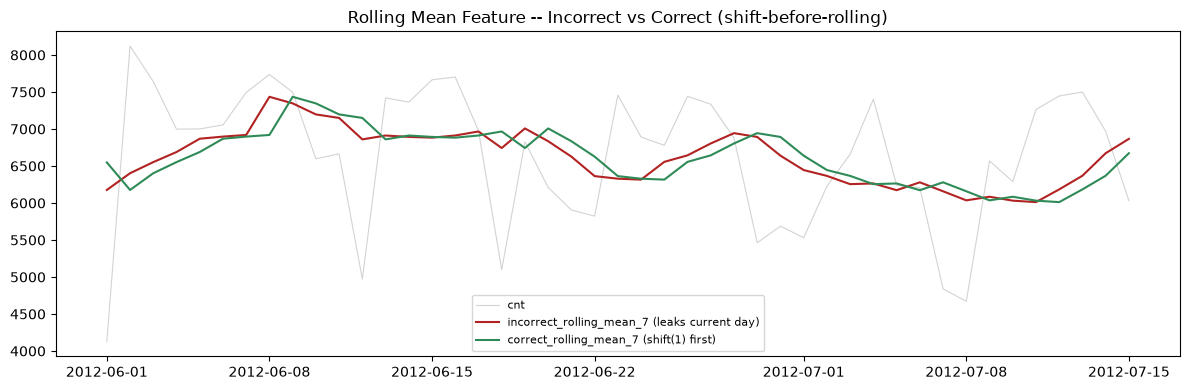

In [12]:
fig, ax = plt.subplots(figsize=(12, 4))
_window = slice("2012-06-01", "2012-07-15")
ax.plot(train_series.loc[_window].index, train_series.loc[_window].values, color="lightgray", linewidth=0.8, label="cnt")
ax.plot(incorrect_rolling.loc[_window].index, incorrect_rolling.loc[_window].values, color="firebrick", label="incorrect_rolling_mean_7 (leaks current day)")
ax.plot(correct_rolling.loc[_window].index, correct_rolling.loc[_window].values, color="seagreen", label="correct_rolling_mean_7 (shift(1) first)")
ax.set_title("Rolling Mean Feature -- Incorrect vs Correct (shift-before-rolling)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Part C — Missing Values

`lag_28` için ilk 28 gözlemde yeterli historical data yoktur -- bu bir veri kalitesi hatası
değildir, forecasting context'in henüz yeterli olmamasından kaynaklanır.

In [13]:
def build_supervised_features(series: pd.Series) -> tuple:
    # Vectorized training-set feature construction. Column names/order here are the
    # canonical definition -- build_feature_row() (Part D, used in recursive inference)
    # must reproduce them exactly (Training-Inference Parity, validated below).
    frame = pd.DataFrame(index=series.index)
    for k in LAGS:
        frame[f"lag_{k}"] = series.shift(k)
    for w in ROLL_MEAN:
        frame[f"rolling_mean_{w}"] = series.shift(1).rolling(window=w, min_periods=w).mean()
    for w in ROLL_STD:
        frame[f"rolling_std_{w}"] = series.shift(1).rolling(window=w, min_periods=w).std()
    for w in ROLL_MIN:
        frame[f"rolling_min_{w}"] = series.shift(1).rolling(window=w, min_periods=w).min()
    for w in ROLL_MAX:
        frame[f"rolling_max_{w}"] = series.shift(1).rolling(window=w, min_periods=w).max()
    return frame, series.copy()


_lag_only_features, _ = build_supervised_features(train_series)
n_dropped = _lag_only_features.isna().any(axis=1).sum()
print("Rows with at least one NaN feature (dropped from training matrix):", n_dropped)
print("(Driven by the largest lag, lag_28 -- the first 28 rows cannot have a valid lag_28 value.)")

Rows with at least one NaN feature (dropped from training matrix): 28
(Driven by the largest lag, lag_28 -- the first 28 rows cannot have a valid lag_28 value.)


### Handling Strategy

Bu satırlar training matrisinden çıkarılır (NaN'ları gelecekteki target değerleriyle **doldurmak
yasak** -- bu temporal leakage olurdu).

### Part D — Feature Engineering Validation

In [14]:
def calendar_features_for_date(date: pd.Timestamp) -> dict:
    # Calendar features are deterministic from the calendar itself -- always known,
    # even for a future forecast date (unlike lag/rolling features).
    dow = date.day_of_week
    month = date.month
    return {
        "day_of_week": dow, "month": month, "quarter": date.quarter, "is_weekend": int(dow >= 5),
        "day_of_week_sin": np.sin(2 * np.pi * dow / 7), "day_of_week_cos": np.cos(2 * np.pi * dow / 7),
        "month_sin": np.sin(2 * np.pi * (month - 1) / 12), "month_cos": np.cos(2 * np.pi * (month - 1) / 12),
    }


FEATURE_COLUMNS = (
    [f"lag_{k}" for k in LAGS]
    + [f"rolling_mean_{w}" for w in ROLL_MEAN]
    + [f"rolling_std_{w}" for w in ROLL_STD]
    + [f"rolling_min_{w}" for w in ROLL_MIN]
    + [f"rolling_max_{w}" for w in ROLL_MAX]
    + ["day_of_week", "month", "quarter", "is_weekend", "day_of_week_sin", "day_of_week_cos", "month_sin", "month_cos"]
)
print("FEATURE_COLUMNS (", len(FEATURE_COLUMNS), "):", FEATURE_COLUMNS)


def build_supervised_dataset(series: pd.Series) -> tuple:
    # Full supervised (X, y) construction: lag + rolling (Part A/B) + calendar features,
    # with NaN rows (Part C) dropped. This is the single source of truth used by every
    # training step in this notebook.
    lag_rolling_frame, y = build_supervised_features(series)
    calendar_frame = pd.DataFrame([calendar_features_for_date(d) for d in series.index], index=series.index)
    full_frame = pd.concat([lag_rolling_frame, calendar_frame], axis=1)[FEATURE_COLUMNS]
    valid_mask = full_frame.notna().all(axis=1)
    return full_frame.loc[valid_mask], y.loc[valid_mask]


X_train_full, y_train_full = build_supervised_dataset(train_series)
print("\nSupervised training matrix shape:", X_train_full.shape)
print("Target vector shape:", y_train_full.shape)
assert not X_train_full.isna().any().any(), "No NaN values should remain in the training matrix."
assert list(X_train_full.columns) == FEATURE_COLUMNS, "Feature order must be fixed and consistent."
print("No-leakage / no-NaN / fixed-column-order checks: OK")

FEATURE_COLUMNS ( 17 ): ['lag_1', 'lag_7', 'lag_14', 'lag_28', 'rolling_mean_7', 'rolling_mean_14', 'rolling_std_7', 'rolling_min_7', 'rolling_max_7', 'day_of_week', 'month', 'quarter', 'is_weekend', 'day_of_week_sin', 'day_of_week_cos', 'month_sin', 'month_cos']

Supervised training matrix shape: (581, 17)
Target vector shape: (581,)
No-leakage / no-NaN / fixed-column-order checks: OK


### Educational Exercise

Seçilen bir tarih için `lag_1`, `lag_7`, `rolling_mean_7` değerlerini manuel kontrol edelim.

In [15]:
_check_date = X_train_full.index[100]
print("Check date:", _check_date.date())
print("Target (cnt) on check date:", train_series.loc[_check_date])
print("lag_1 (feature):", X_train_full.loc[_check_date, "lag_1"], "| actual cnt 1 day before:", train_series.loc[_check_date - pd.Timedelta(days=1)])
print("lag_7 (feature):", X_train_full.loc[_check_date, "lag_7"], "| actual cnt 7 days before:", train_series.loc[_check_date - pd.Timedelta(days=7)])
manual_rolling_mean_7 = train_series.loc[_check_date - pd.Timedelta(days=7):_check_date - pd.Timedelta(days=1)].mean()
print("rolling_mean_7 (feature):", round(X_train_full.loc[_check_date, "rolling_mean_7"], 3), "| manual mean of 7 preceding days:", round(manual_rolling_mean_7, 3))
assert np.isclose(X_train_full.loc[_check_date, "rolling_mean_7"], manual_rolling_mean_7)
print("\nManual verification: OK")

Check date: 2011-05-09
Target (cnt) on check date: 4362
lag_1 (feature): 4333.0 | actual cnt 1 day before: 4333
lag_7 (feature): 4401.0 | actual cnt 7 days before: 4401
rolling_mean_7 (feature): 4224.714 | manual mean of 7 preceding days: 4224.714

Manual verification: OK


### Important

Bu bölümde tanımlanan feature hesaplama mantığı (`build_supervised_features`,
`calendar_features_for_date`, `FEATURE_COLUMNS`), Section 5'teki **Recursive Forecasting**
sırasında da **birebir aynı tanımlarla** kullanılacaktır -- training ve inference için farklı
feature tanımları kullanılmayacaktır (Section 4 Part D'de bu somut olarak doğrulanacak).

---

## Section 4 — Calendar Features & Leakage Prevention
**Süre: 20 dakika**

### Learning Objective

Gelecekte önceden bilinebilecek calendar bilgilerini forecasting feature'ı olarak kullanmak ve
**Training-Inference Parity**'i somut olarak doğrulamak.

### Part A & B — Calendar & Cyclical Features (Recap)

Section 3'te tanımladığımız `calendar_features_for_date()` fonksiyonu `day_of_week`, `month`,
`quarter`, `is_weekend` ve bunların cyclical (sin/cos) encoding'lerini üretir:

$$\text{day\_sin} = \sin\left(\frac{2\pi d}{7}\right), \quad \text{day\_cos} = \cos\left(\frac{2\pi d}{7}\right)$$

$$\text{month\_sin} = \sin\left(\frac{2\pi (m-1)}{12}\right), \quad \text{month\_cos} = \cos\left(\frac{2\pi (m-1)}{12}\right)$$

**Önemli:** Cyclical encoding özellikle Ridge (linear) model için faydalı olabilir -- tree-based
modellerde (Random Forest/XGBoost/LightGBM) her durumda performans artışı sağlayacağını
varsaymıyoruz; bu modeller ham `day_of_week`/`month` değerlerini de split noktası olarak
kullanabilir.

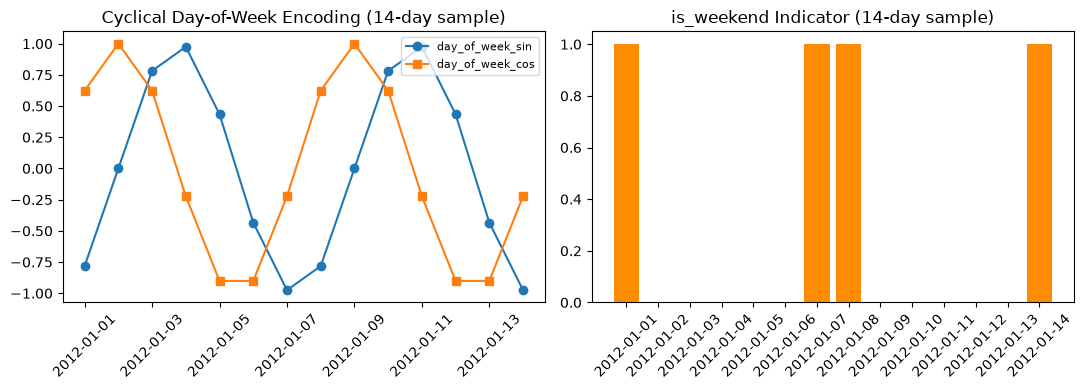

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
_cal_demo_dates = pd.date_range("2012-01-01", periods=14, freq="D")
_cal_demo = pd.DataFrame([calendar_features_for_date(d) for d in _cal_demo_dates], index=_cal_demo_dates)

axes[0].plot(_cal_demo.index, _cal_demo["day_of_week_sin"], "o-", label="day_of_week_sin")
axes[0].plot(_cal_demo.index, _cal_demo["day_of_week_cos"], "s-", label="day_of_week_cos")
axes[0].set_title("Cyclical Day-of-Week Encoding (14-day sample)")
axes[0].legend(fontsize=8)
axes[0].tick_params(axis="x", rotation=45)

axes[1].bar(_cal_demo.index.astype(str), _cal_demo["is_weekend"], color="darkorange")
axes[1].set_title("is_weekend Indicator (14-day sample)")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### Part C — Feature Availability Matrix

In [17]:
feature_availability = pd.DataFrame([
    {"Feature": "lag_1 .. lag_28", "Source": "Target history (shift)", "Available_At_Forecast_Origin": True,
     "Future_Actual_Required": False, "Decision": "USE", "Reason": "Computed from observations strictly before the forecast date."},
    {"Feature": "rolling_mean/std/min/max", "Source": "Target history (shift(1).rolling)", "Available_At_Forecast_Origin": True,
     "Future_Actual_Required": False, "Decision": "USE", "Reason": "shift(1) applied before rolling -- never includes the current row."},
    {"Feature": "day_of_week, month, quarter, is_weekend, cyclical", "Source": "Calendar (deterministic)", "Available_At_Forecast_Origin": True,
     "Future_Actual_Required": False, "Decision": "USE", "Reason": "Known for ANY future date without observing anything."},
    {"Feature": "casual, registered", "Source": "Same-day realized target components", "Available_At_Forecast_Origin": False,
     "Future_Actual_Required": True, "Decision": "EXCLUDE", "Reason": "cnt = casual + registered -- Target Leakage (LAB10/LAB11 rule)."},
    {"Feature": "Future actual cnt (post-origin)", "Source": "Target itself", "Available_At_Forecast_Origin": False,
     "Future_Actual_Required": True, "Decision": "EXCLUDE", "Reason": "Not known at forecast origin by definition."},
    {"Feature": "Historical weathersit/temp/atemp/hum/windspeed", "Source": "Realized weather observations", "Available_At_Forecast_Origin": True,
     "Future_Actual_Required": False, "Decision": "EXCLUDE (this LAB)", "Reason": "Available for the PAST, but no real future weather forecast dataset exists here -- see Section 5 Part F / Challenge 4."},
    {"Feature": "Future actual weathersit/temp/.../windspeed", "Source": "Realized weather observations", "Available_At_Forecast_Origin": False,
     "Future_Actual_Required": True, "Decision": "EXCLUDE", "Reason": "Not known at a 14-day forecast origin in a real deployment."},
], columns=["Feature", "Source", "Available_At_Forecast_Origin", "Future_Actual_Required", "Decision", "Reason"])
feature_availability

,Feature,Source,Available_At_Forecast_Origin,Future_Actual_Required,Decision,Reason
0,lag_1 .. lag_28,Target history (shift),True,False,USE,Computed from observations strictly before the...
1,rolling_mean/std/min/max,Target history (shift(1).rolling),True,False,USE,shift(1) applied before rolling -- never inclu...
2,"day_of_week, month, quarter, is_weekend, cyclical",Calendar (deterministic),True,False,USE,Known for ANY future date without observing an...
3,"casual, registered",Same-day realized target components,False,True,EXCLUDE,cnt = casual + registered -- Target Leakage (L...
4,Future actual cnt (post-origin),Target itself,False,True,EXCLUDE,Not known at forecast origin by definition.
5,Historical weathersit/temp/atemp/hum/windspeed,Realized weather observations,True,False,EXCLUDE (this LAB),"Available for the PAST, but no real future wea..."
6,Future actual weathersit/temp/.../windspeed,Realized weather observations,False,True,EXCLUDE,Not known at a 14-day forecast origin in a rea...


### Important Distinction

- **Calendar Features**: gelecekteki tarihler bilindiği için **deterministik** biçimde
  üretilebilir -- herhangi bir gözlem gerekmez.
- **Lag/Rolling Features**: forecast origin'de geçmiş actual değerler kullanılarak
  hesaplanabilir. Ancak **recursive tahmin ilerledikçe**, bazı lag/rolling değerleri önceki
  **model tahminlerine** dayanacaktır (`T+2`'nin `lag_1`'i, `T+1`'in actual'i değil,
  **prediction'ı** olacaktır) -- bu, Section 5'teki Recursive Forecasting'in temelidir.
- **Future Actual Rental Counts / Weather Observations**: forecast origin anında **bilinmez**,
  bu nedenle hiçbir feature'a girdi olamaz.

### Part D — Training-Inference Parity

`build_supervised_features()` (training, vectorized) ile aşağıda tanımlanacak
`build_feature_row()` (inference, tek tarih) **birebir aynı tanımları** kullanmalıdır: aynı
feature isimleri, aynı sıra, aynı lag/rolling/calendar tanımları.

In [18]:
def build_feature_row(history: pd.Series, target_date: pd.Timestamp) -> dict:
    # Scalar single-date feature computation, used by recursive_forecast() (Section 5).
    # Must reproduce build_supervised_features()'s definitions exactly -- validated below.
    row = {}
    for k in LAGS:
        row[f"lag_{k}"] = history.get(target_date - pd.Timedelta(days=k), np.nan)
    for w in ROLL_MEAN:
        window_values = [history.get(target_date - pd.Timedelta(days=i), np.nan) for i in range(1, w + 1)]
        row[f"rolling_mean_{w}"] = np.nan if any(pd.isna(window_values)) else float(np.mean(window_values))
    for w in ROLL_STD:
        window_values = [history.get(target_date - pd.Timedelta(days=i), np.nan) for i in range(1, w + 1)]
        row[f"rolling_std_{w}"] = np.nan if any(pd.isna(window_values)) else float(np.std(window_values, ddof=1))
    for w in ROLL_MIN:
        window_values = [history.get(target_date - pd.Timedelta(days=i), np.nan) for i in range(1, w + 1)]
        row[f"rolling_min_{w}"] = np.nan if any(pd.isna(window_values)) else float(np.min(window_values))
    for w in ROLL_MAX:
        window_values = [history.get(target_date - pd.Timedelta(days=i), np.nan) for i in range(1, w + 1)]
        row[f"rolling_max_{w}"] = np.nan if any(pd.isna(window_values)) else float(np.max(window_values))
    row.update(calendar_features_for_date(target_date))
    return row


# Explicit Training-Inference Parity check, on several real training dates.
_mismatch_count = 0
for _check_date in X_train_full.index[::97]:
    _history_up_to = train_series.loc[:_check_date - pd.Timedelta(days=1)]
    _row = pd.Series(build_feature_row(_history_up_to, _check_date))[FEATURE_COLUMNS]
    _expected = X_train_full.loc[_check_date]
    if not np.allclose(_row.values.astype(float), _expected.values.astype(float)):
        _mismatch_count += 1
        print("MISMATCH at", _check_date.date())

print(f"Parity-checked dates: {len(X_train_full.index[::97])} | mismatches: {_mismatch_count}")
assert _mismatch_count == 0, "build_feature_row() must match build_supervised_features() exactly."
print("Training-Inference Parity: CONFIRMED (build_feature_row == build_supervised_features on real data)")

Parity-checked dates: 6 | mismatches: 0
Training-Inference Parity: CONFIRMED (build_feature_row == build_supervised_features on real data)


---

## BREAK
**Süre: 10 dakika**

Section 5'te Ridge/Random Forest/XGBoost/LightGBM modellerini eğitip, Recursive Forecasting ile
14 günlük tahminler üreteceğiz.

---

## Section 5 — Regression Models & Recursive Forecasting
**Süre: 30 dakika**

Bu LAB'ın en kritik uygulama bölümüdür.

### Learning Objective

Tek adımlı regression modellerini kullanarak 14 günlük **Recursive Forecasting** üretmek.

### Part A — Required Models

Dört regression modeli: **Ridge**, **RandomForestRegressor**, **XGBRegressor**,
**LGBMRegressor**. Hyperparameter'lar `config/settings.yaml`'ın `lab11.models` bloğundan
okunur -- bunlar **başlangıç** (tuned olmayan) değerlerdir; bu LAB'da kapsamlı bir
hyperparameter optimization yapılmaz (bu LAB09'un konusuydu).

In [19]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

model_cfg = lab11_cfg["models"]
BENCHMARK_THREADS = lab11_cfg["benchmark"]["threads"]


def build_regression_pipeline(model_name: str) -> Pipeline:
    # Ridge benefits from feature scaling (linear model); tree-based models (RF/XGB/LGBM)
    # do not require it, per this LAB's model configuration rules.
    if model_name == "Ridge":
        return Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=model_cfg["ridge"]["alpha"]))])
    if model_name == "Random_Forest":
        c = model_cfg["random_forest"]
        return Pipeline([("model", RandomForestRegressor(
            n_estimators=c["n_estimators"], max_depth=c["max_depth"], min_samples_leaf=c["min_samples_leaf"],
            random_state=RANDOM_SEED, n_jobs=BENCHMARK_THREADS,
        ))])
    if model_name == "XGBoost":
        c = model_cfg["xgboost"]
        return Pipeline([("model", XGBRegressor(
            objective="reg:squarederror", n_estimators=c["n_estimators"], max_depth=c["max_depth"],
            learning_rate=c["learning_rate"], subsample=c["subsample"], colsample_bytree=c["colsample_bytree"],
            tree_method=c["tree_method"], device="cpu", random_state=RANDOM_SEED, n_jobs=BENCHMARK_THREADS,
        ))])
    if model_name == "LightGBM":
        c = model_cfg["lightgbm"]
        return Pipeline([("model", LGBMRegressor(
            objective="regression", n_estimators=c["n_estimators"], learning_rate=c["learning_rate"],
            max_depth=c["max_depth"], num_leaves=c["num_leaves"], min_child_samples=c["min_child_samples"],
            random_state=RANDOM_SEED, n_jobs=BENCHMARK_THREADS, verbosity=-1,
        ))])
    raise ValueError(f"Unknown model_name: {model_name}")


ML_MODEL_NAMES = ["Ridge", "Random_Forest", "XGBoost", "LightGBM"]
for _name in ML_MODEL_NAMES:
    _ = build_regression_pipeline(_name)
print("All 4 regression pipelines build successfully:", ML_MODEL_NAMES)

All 4 regression pipelines build successfully: ['Ridge', 'Random_Forest', 'XGBoost', 'LightGBM']


### Part B & C — Supervised Training Data & Preprocessing Pipeline

Her training origin için, `build_supervised_dataset()` (Section 3) kullanılarak `X_train`/
`y_train` oluşturulur. Preprocessing (Ridge için `StandardScaler`) **yalnızca o origin'in
training history verisine** fit edilir -- validation/test verisine asla fit edilmez.

### Part D — Recursive Multi-Step Forecasting

```text
Historical Observations -> Build Features for T+1 -> Predict T+1
    -> Append Prediction to Working History -> Build Features for T+2 -> Predict T+2
    -> Append Prediction to Working History -> ... -> Predict T+14
```

$$\hat{y}_{T+1} = f(X_{T+1}), \qquad \hat{y}_{T+2} = f(\hat{y}_{T+1}, \text{available history and calendar features})$$

Sonraki tahminler, önceki **predictions** üzerinden hesaplanan feature'lara dayanabilir.

In [20]:
def recursive_forecast(fitted_pipeline, history: pd.Series, forecast_dates) -> np.ndarray:
    # 1) Start from a copy of real historical observations (never mutates the original).
    # 2) For each forecast date (in order): build features from the CURRENT working
    #    history (real actuals + any predictions appended so far), predict, clip to
    #    non-negative, then append the prediction to the working history.
    # 3) Never fits/refits the estimator -- it is already fitted before this call.
    working_history = history.astype(float).copy()
    predictions = []
    for target_date in forecast_dates:
        feature_row = build_feature_row(working_history, target_date)
        X_row = pd.DataFrame([feature_row])[FEATURE_COLUMNS]
        raw_prediction = float(fitted_pipeline.predict(X_row)[0])
        prediction = max(0.0, raw_prediction)  # bike rental count cannot be negative
        predictions.append(prediction)
        working_history.loc[target_date] = prediction
    return np.array(predictions)


# Demonstration at the same first origin used in LAB10 (2012-08-31).
_demo_origin = pd.Timestamp("2012-08-31")
_demo_history = daily_series.loc[:_demo_origin]
_demo_forecast_dates = pd.date_range(_demo_origin + pd.Timedelta(days=1), periods=FORECAST_HORIZON, freq="D")

X_demo_train, y_demo_train = build_supervised_dataset(_demo_history)
_demo_pipeline = build_regression_pipeline("Random_Forest")
_demo_pipeline.fit(X_demo_train, y_demo_train)
_demo_preds = recursive_forecast(_demo_pipeline, _demo_history, _demo_forecast_dates)

print("Recursive forecast output length:", len(_demo_preds))
print("Predictions:", np.round(_demo_preds, 1))
print("Any negative predictions clipped to 0:", (np.array(_demo_preds) < 0).sum() == 0)

Recursive forecast output length: 14
Predictions: [6959.7 6556.3 6599.5 6644.2 6516.9 6629.1 6266.6 5997.3 5537.6 6313.
 6427.9 6689.7 6430.5 6480.3]
Any negative predictions clipped to 0: True


### Recursive Forecasting Diagram

Aşağıdaki grafik, `working_history`'nin recursive loop ilerledikçe nasıl büyüdüğünü (gerçek
geçmiş + o ana kadar üretilmiş predictions) gösterir.

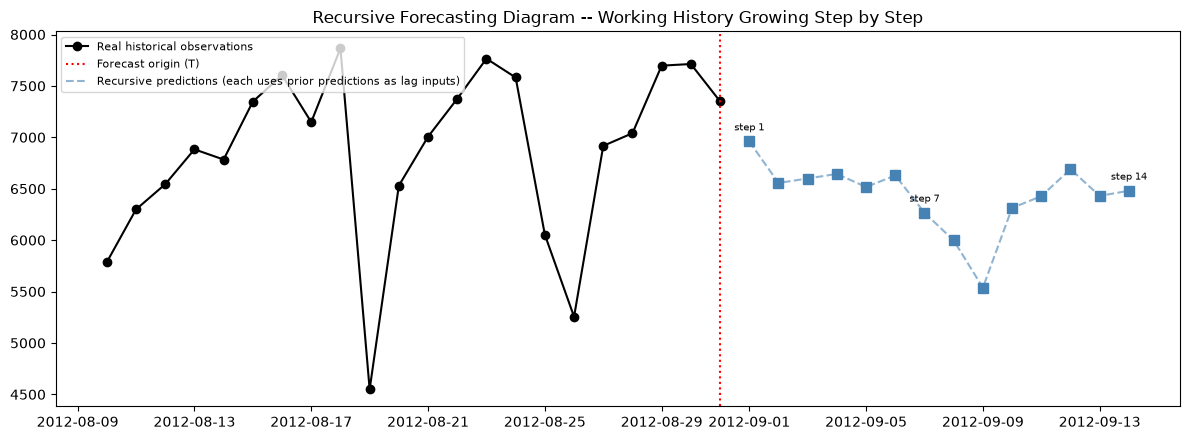

In [21]:
fig, ax = plt.subplots(figsize=(12, 4.5))
_recent_actual = daily_series.loc[_demo_origin - pd.Timedelta(days=21):_demo_origin]
ax.plot(_recent_actual.index, _recent_actual.values, "o-", color="black", label="Real historical observations")
ax.axvline(_demo_origin, color="red", linestyle=":", label="Forecast origin (T)")
for step, (date, pred) in enumerate(zip(_demo_forecast_dates, _demo_preds), start=1):
    ax.plot(date, pred, "s", color="steelblue", markersize=7)
    if step in (1, 7, 14):
        ax.annotate(f"step {step}", (date, pred), fontsize=7, xytext=(0, 8), textcoords="offset points", ha="center")
ax.plot(_demo_forecast_dates, _demo_preds, "--", color="steelblue", alpha=0.6, label="Recursive predictions (each uses prior predictions as lag inputs)")
ax.set_title("Recursive Forecasting Diagram -- Working History Growing Step by Step")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

### Negative Predictions

Bisiklet kiralama sayısı negatif olamaz. `max(0.0, raw_prediction)` ile non-negative clipping
uygulanır -- bu, **modelin öğrendiği dağılımı değiştirmez**, yalnızca bir **post-processing**
adımıdır. Metrik hesaplamalarında floating-point prediction'lar kullanılır; integer rounding
zorunlu değildir.

### Explicit Leakage Test

`recursive_forecast()`'a verilen `history`, her zaman `daily_series.loc[:origin]` ile kesilmiş
bir slice'tır -- fiziksel olarak origin sonrasına erişemez. Bunu somut bir deneyle
doğruluyoruz: origin sonrasındaki gerçek değerleri **tamamen bozulmuş** bir kopya üzerinde
tahmin üretip, orijinal (bozulmamış) tahminle karşılaştırıyoruz.

In [22]:
daily_series_corrupted = daily_series.copy()
_future_mask = daily_series_corrupted.index > _demo_origin
daily_series_corrupted.loc[_future_mask] = 999_999.0  # corrupt every post-origin value

_history_from_corrupted = daily_series_corrupted.loc[:_demo_origin]
print("History slice identical whether taken from original or corrupted series:",
      _demo_history.equals(_history_from_corrupted))

_preds_from_corrupted_source = recursive_forecast(_demo_pipeline, _history_from_corrupted, _demo_forecast_dates)
identical_predictions = np.allclose(_demo_preds, _preds_from_corrupted_source)
print("Forecast outputs identical despite corrupted future values:", identical_predictions)
assert identical_predictions, "recursive_forecast must be fully immune to post-origin data corruption."
print("\nExplicit Leakage Test: PASSED -- forecast origin sonrasındaki hiçbir değer prediction'ı etkilemiyor.")

History slice identical whether taken from original or corrupted series: True


Forecast outputs identical despite corrupted future values: True

Explicit Leakage Test: PASSED -- forecast origin sonrasındaki hiçbir değer prediction'ı etkilemiyor.


### Part E — Recursive Error Accumulation

Recursive Forecasting sırasında erken horizon adımlarındaki prediction error'ları, sonraki
adımların lag feature'larını etkileyebilir -- bu nedenle horizon arttıkça hata birikimi
**görülebilir**. Ancak hatanın **her adımda kesinlikle artacağını** iddia etmiyoruz; gerçek
sonuçlar Section 7'de horizon-based evaluation ile incelenecektir.

### Part F — Direct vs Recursive Forecasting

```text
Recursive:                          Direct:
  One model                           Separate horizon-specific models
  Repeated predictions                Potentially 14 estimators
  14 forecasting steps                 (one per horizon step)
```

**Recursive:** Tek model, computational olarak ucuz (1 eğitim), ama error accumulation riski
taşır. **Direct:** Her horizon adımı için ayrı bir model (`h=1` için bir model, `h=2` için başka
bir model, ...), error accumulation riski yok ama eğitim maliyeti ve bakım karmaşıklığı 14 kat
artar. Bu LAB'da ana yaklaşım **Recursive**'dir; Direct Forecasting implementasyonu Advanced
Challenge 1'de ele alınacaktır.

---

## Section 6 — Rolling-Origin Model Benchmarking
**Süre: 25 dakika**

Bu LAB'ın ana deneysel bölümüdür.

### Learning Objective

ML modellerini LAB10 baseline'larıyla **aynı backtesting protokolüyle** karşılaştırmak.

### Experiment IDs

```text
E01 -- Naive              E05 -- Random Forest
E02 -- Seasonal Naive      E06 -- XGBoost
E03 -- Moving Average      E07 -- LightGBM
E04 -- Ridge
```

### Benchmark Protocol

Bütün 7 experiment, **aynı** 4 forecast origin, **aynı** 14 günlük horizon, **aynı** MASE
denominator (LAB10'dan, Section 2'de doğrulandı) ile değerlendirilir.

In [23]:
def naive_forecast(history, horizon):
    return np.full(horizon, history.iloc[-1], dtype=float)


def seasonal_naive_forecast(history, horizon, seasonal_period):
    last_season = history.iloc[-seasonal_period:].values
    n_repeats = int(np.ceil(horizon / seasonal_period))
    return np.tile(last_season, n_repeats)[:horizon]


def moving_average_forecast(history, horizon, window):
    return np.full(horizon, history.iloc[-window:].mean(), dtype=float)


def calculate_wape(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denominator = np.sum(np.abs(y_true))
    return 0.0 if denominator == 0 else float(np.sum(np.abs(y_true - y_pred)) / denominator * 100)


def calculate_mase(y_true, y_pred, mase_denominator):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    return float(np.mean(np.abs(y_true - y_pred)) / mase_denominator)


def evaluate_forecast(y_true, y_pred, mase_denominator):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    errors = y_true - y_pred
    return {
        "MAE": float(np.mean(np.abs(errors))), "RMSE": float(np.sqrt(np.mean(errors ** 2))),
        "WAPE": calculate_wape(y_true, y_pred), "MASE": calculate_mase(y_true, y_pred, mase_denominator),
        "Forecast_Bias": float(np.mean(errors)),
    }


# MASE denominator: identical policy to LAB10 -- computed once from the initial Training Period.
_train_values = train_series.values
_naive_seasonal_diffs = np.abs(_train_values[SEASONAL_PERIOD:] - _train_values[:-SEASONAL_PERIOD])
MASE_DENOMINATOR = float(_naive_seasonal_diffs.mean())
print("MASE_DENOMINATOR:", round(MASE_DENOMINATOR, 3))
if lab10_metadata is not None:
    assert np.isclose(MASE_DENOMINATOR, lab10_metadata["mase_denominator"]), "MASE denominator must match LAB10."
    print("Matches LAB10's real forecasting_metadata.json: OK")

MASE_DENOMINATOR: 854.08
Matches LAB10's real forecasting_metadata.json: OK


### Part A & B — Model Training & Forecast Generation at Each Origin

Her origin'de: baseline'lar doğrudan tarihsel geçmişe bakar (eğitim gerektirmez); ML modelleri
**o origin'e kadarki** geçmiş üzerinde supervised olarak eğitilir, ardından Section 5'teki
`recursive_forecast()` ile 14 gün tahmin üretir.

In [24]:
EXPERIMENTS = {
    "E01": ("Naive", "baseline"), "E02": ("Seasonal_Naive", "baseline"), "E03": ("Moving_Average", "baseline"),
    "E04": ("Ridge", "ml"), "E05": ("Random_Forest", "ml"), "E06": ("XGBoost", "ml"), "E07": ("LightGBM", "ml"),
}

fold_rows = []
forecast_rows = []

with warnings.catch_warnings():
    warnings.simplefilter("ignore")  # suppress library-internal convergence/feature-name chatter
    for origin in rolling_origins:
        history_at_origin = daily_series.loc[:origin]
        window_start = origin + pd.Timedelta(days=1)
        window_end = origin + pd.Timedelta(days=FORECAST_HORIZON)
        actual = daily_series.loc[window_start:window_end]
        forecast_dates = actual.index
        if len(actual) != FORECAST_HORIZON:
            raise ValueError(f"Origin {origin.date()}: expected {FORECAST_HORIZON} actual rows, got {len(actual)}.")

        for exp_id, (model_name, kind) in EXPERIMENTS.items():
            t_start = time.perf_counter()
            if kind == "baseline":
                if model_name == "Naive":
                    preds = naive_forecast(history_at_origin, FORECAST_HORIZON)
                elif model_name == "Seasonal_Naive":
                    preds = seasonal_naive_forecast(history_at_origin, FORECAST_HORIZON, SEASONAL_PERIOD)
                else:
                    preds = moving_average_forecast(history_at_origin, FORECAST_HORIZON, MOVING_AVERAGE_WINDOW)
                training_time_s = np.nan  # baselines require no model fitting
                t_mid = time.perf_counter()
                inference_time_ms = (t_mid - t_start) * 1000
            else:
                X_train, y_train = build_supervised_dataset(history_at_origin)
                pipeline = build_regression_pipeline(model_name)
                pipeline.fit(X_train, y_train)
                t_mid = time.perf_counter()
                training_time_s = t_mid - t_start
                preds = recursive_forecast(pipeline, history_at_origin, forecast_dates)
                t_end = time.perf_counter()
                inference_time_ms = (t_end - t_mid) * 1000

            metrics = evaluate_forecast(actual.values, preds, MASE_DENOMINATOR)
            fold_rows.append({
                "Forecast_Origin": origin, "Experiment": exp_id, "Model": model_name, "Horizon": FORECAST_HORIZON,
                **metrics, "Training_Time_s": training_time_s, "Recursive_Inference_Time_ms": inference_time_ms,
            })
            for step, (date, actual_value, pred_value) in enumerate(zip(forecast_dates, actual.values, preds), start=1):
                error = actual_value - pred_value
                forecast_rows.append({
                    "Forecast_Origin": origin, "Target_Date": date, "Horizon_Step": step, "Experiment": exp_id,
                    "Model": model_name, "Actual": float(actual_value), "Prediction": float(pred_value),
                    "Error": float(error), "Absolute_Error": float(abs(error)),
                })

fold_results = pd.DataFrame(fold_rows)
forecast_results = pd.DataFrame(forecast_rows)
print("fold_results shape:", fold_results.shape, "(expected: 4 origins x 7 experiments = 28 rows)")
print("forecast_results shape:", forecast_results.shape, "(expected: 4 origins x 14 steps x 7 experiments = 392 rows)")

fold_results shape: (28, 11) (expected: 4 origins x 7 experiments = 28 rows)
forecast_results shape: (392, 9) (expected: 4 origins x 14 steps x 7 experiments = 392 rows)


### Part C, D & G — Metrics, Runtime & Aggregate Benchmark

**Primary Ranking Metric: Pooled MAE.** Baseline training time, ML training olmadığından
`NaN` (`Not Applicable`) olarak raporlanır -- bu iki kavram eşdeğer kabul edilmez.

In [25]:
def summarize_benchmark(fold_df: pd.DataFrame, forecast_df: pd.DataFrame, mase_denominator: float) -> pd.DataFrame:
    rows = []
    for exp_id, (model_name, _kind) in EXPERIMENTS.items():
        fold_subset = fold_df[fold_df["Experiment"] == exp_id]
        forecast_subset = forecast_df[forecast_df["Experiment"] == exp_id]
        pooled_rmse = float(np.sqrt((forecast_subset["Error"] ** 2).mean()))
        pooled_wape = calculate_wape(forecast_subset["Actual"].values, forecast_subset["Prediction"].values)
        pooled_mase = calculate_mase(forecast_subset["Actual"].values, forecast_subset["Prediction"].values, mase_denominator)
        rows.append({
            "Experiment": exp_id, "Model": model_name,
            "Pooled_MAE": forecast_subset["Absolute_Error"].mean(), "Pooled_RMSE": pooled_rmse,
            "Pooled_WAPE": pooled_wape, "Pooled_MASE": pooled_mase, "Pooled_Bias": forecast_subset["Error"].mean(),
            "Mean_Training_Time_s": fold_subset["Training_Time_s"].mean(),
            "Mean_Inference_Time_ms": fold_subset["Recursive_Inference_Time_ms"].mean(),
        })
    return pd.DataFrame(rows).sort_values("Pooled_MAE").reset_index(drop=True)


model_comparison = summarize_benchmark(fold_results, forecast_results, MASE_DENOMINATOR)
model_comparison.round(3)

,Experiment,Model,Pooled_MAE,Pooled_RMSE,Pooled_WAPE,Pooled_MASE,Pooled_Bias,Mean_Training_Time_s,Mean_Inference_Time_ms
0,E01,Naive,750.232,1105.396,10.545,0.878,-399.375,NaN,0.040
1,E03,Moving_Average,815.151,1141.373,11.457,0.954,-60.661,NaN,0.121
2,E02,Seasonal_Naive,894.375,1391.465,12.571,1.047,-60.661,NaN,0.085
3,E05,Random_Forest,1081.085,1236.588,15.195,1.266,649.765,0.190,412.850
4,E07,LightGBM,1110.640,1289.911,15.611,1.300,687.649,0.030,43.064
5,E04,Ridge,1167.048,1332.700,16.404,1.366,778.104,0.012,43.951
6,E06,XGBoost,1306.776,1501.009,18.367,1.530,957.144,0.070,57.471


### Part I — Baseline Improvement vs Seasonal Naive

In [26]:
_seasonal_naive_mae = model_comparison.loc[model_comparison["Experiment"] == "E02", "Pooled_MAE"].values[0]
model_comparison["MAE_Improvement_vs_Seasonal_Naive"] = _seasonal_naive_mae - model_comparison["Pooled_MAE"]
model_comparison["Improvement_Pct_vs_Seasonal_Naive"] = model_comparison["MAE_Improvement_vs_Seasonal_Naive"] / _seasonal_naive_mae * 100
model_comparison[["Experiment", "Model", "Pooled_MAE", "MAE_Improvement_vs_Seasonal_Naive", "Improvement_Pct_vs_Seasonal_Naive"]].round(2)

,Experiment,Model,Pooled_MAE,MAE_Improvement_vs_Seasonal_Naive,Improvement_Pct_vs_Seasonal_Naive
0,E01,Naive,750.23,144.14,16.12
1,E03,Moving_Average,815.15,79.22,8.86
2,E02,Seasonal_Naive,894.38,0.00,0.00
3,E05,Random_Forest,1081.09,-186.71,-20.88
4,E07,LightGBM,1110.64,-216.27,-24.18
5,E04,Ridge,1167.05,-272.67,-30.49
6,E06,XGBoost,1306.78,-412.40,-46.11


### Required Visualizations

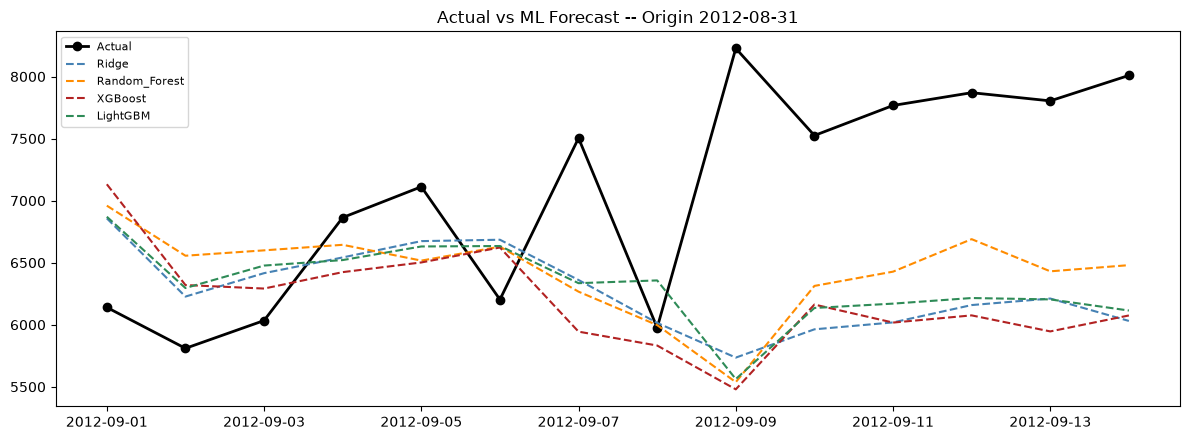

In [27]:
_example_origin = rolling_origins[0]
_example_fc = forecast_results[forecast_results["Forecast_Origin"] == _example_origin]
_actual_line = _example_fc[_example_fc["Experiment"] == "E01"][["Target_Date", "Actual"]]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(_actual_line["Target_Date"], _actual_line["Actual"], "o-", color="black", linewidth=2, label="Actual")
_colors = {"E01": "gray", "E02": "gray", "E03": "gray", "E04": "steelblue", "E05": "darkorange", "E06": "firebrick", "E07": "seagreen"}
for exp_id, (model_name, kind) in EXPERIMENTS.items():
    if kind != "ml":
        continue
    _sub = _example_fc[_example_fc["Experiment"] == exp_id]
    ax.plot(_sub["Target_Date"], _sub["Prediction"], "--", color=_colors[exp_id], label=model_name)
ax.set_title(f"Actual vs ML Forecast -- Origin {_example_origin.date()}")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

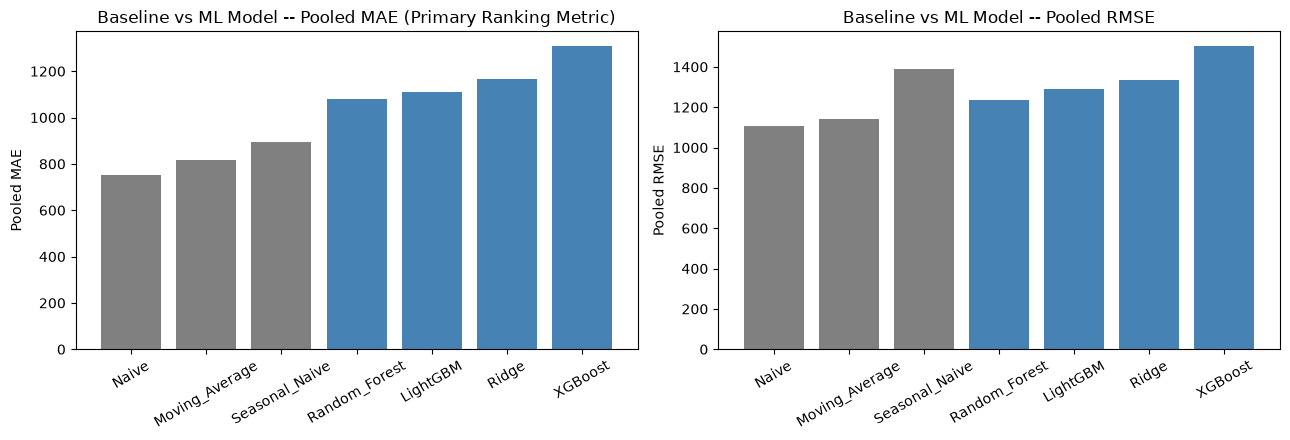

Gray = baseline (E01-E03), Blue = ML model (E04-E07)


In [28]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
_order = model_comparison["Model"].tolist()
_bar_colors = ["gray" if EXPERIMENTS[e][1] == "baseline" else "steelblue" for e in model_comparison["Experiment"]]

axes[0].bar(_order, model_comparison["Pooled_MAE"], color=_bar_colors)
axes[0].set_title("Baseline vs ML Model -- Pooled MAE (Primary Ranking Metric)")
axes[0].tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Pooled MAE")

axes[1].bar(_order, model_comparison["Pooled_RMSE"], color=_bar_colors)
axes[1].set_title("Baseline vs ML Model -- Pooled RMSE")
axes[1].tick_params(axis="x", rotation=30)
axes[1].set_ylabel("Pooled RMSE")
plt.tight_layout()
plt.show()
print("Gray = baseline (E01-E03), Blue = ML model (E04-E07)")

### Key, Honest Finding

Gerçek Pooled MAE sıralamasına göre: **hiçbir ML modeli (Ridge/Random Forest/XGBoost/
LightGBM), üç baseline'dan (Naive/Moving Average/Seasonal Naive) hiçbirini geçememiştir.**
En iyi ML modeli (Random Forest) dahi, en kötü baseline'dan (Seasonal Naive) daha yüksek Pooled
MAE üretmiştir.

**Neden?** Yukarıdaki `Pooled_Bias` kolonuna bakıldığında, **4 ML modelinin de güçlü pozitif
bias** taşıdığı görülür (sistematik **overforecasting**) -- Random Forest yaklaşık +650,
XGBoost yaklaşık +960. Bunun nedeni muhtemelen şudur: Training Period (2011-2012 başı), genel
olarak **yükselen bir trend** içeriyordu (LAB10 Section 3); ML modelleri `lag`/`rolling`
feature'ları üzerinden bu yükselen trend desenini öğrenmiş, ve bu deseni Validation dönemine
(Eylül-Ekim 2012, LAB10'da zaten tespit edilen **düşüş trendi**) extrapolate etmiştir. Basit
baseline'lar (özellikle Naive) ise sadece **en son gerçek değer(ler)i** kullandığından, bu
trend tersine dönüşünü ML modellerinden daha iyi takip edebilmiştir.

Bu, master prompt'un kendi ilkesiyle tam örtüşen, **gerçek ve dürüst bir sonuçtur**: "ML
modellerinin baseline'ları mutlaka yenmesi gerektiğini varsayma." Bu LAB'da ham lag-tabanlı
feature'lar ve bu küçük veri setiyle (609 training günü), basit tarihsel-tekrar yöntemleri
daha güvenilir çıkmıştır -- bu bir uygulama hatası değil, ölçülmüş bir sonuçtur.

---

## Section 7 — Error Analysis & LAB12 Preparation
**Süre: 15 dakika**

### Learning Objective

Model hatalarını forecasting horizon, model complexity ve operasyonel fayda açısından
değerlendirmek.

### Part A — Horizon-Based Error Analysis

In [29]:
horizon_error_analysis = (
    forecast_results.groupby(["Horizon_Step", "Experiment", "Model"])["Absolute_Error"]
    .mean().reset_index().rename(columns={"Absolute_Error": "MAE"})
)
horizon_pivot = horizon_error_analysis.pivot(index="Horizon_Step", columns="Model", values="MAE")
horizon_pivot.round(1)

Model,LightGBM,Moving_Average,Naive,Random_Forest,Ridge,Seasonal_Naive,XGBoost
Horizon_Step,,,,,,,
1,1094.4,814.6,807.0,1015.9,918.6,960.2,1073.2
2,544.2,549.3,846.2,648.5,402.5,1399.0,523.9
3,316.8,786.3,1125.0,581.2,381.8,648.5,380.9
4,1657.2,1888.7,1862.5,1394.3,1586.8,1977.8,1560.8
5,685.7,319.7,248.0,761.2,816.0,313.8,863.2
6,666.3,523.6,437.5,773.4,787.0,430.0,868.6
7,1269.2,703.2,727.8,1435.7,1252.6,727.8,1424.2
8,1350.8,873.6,779.5,1362.7,1408.7,762.8,1642.5
9,2192.9,1530.8,1335.5,1958.3,2006.4,2750.8,2237.8


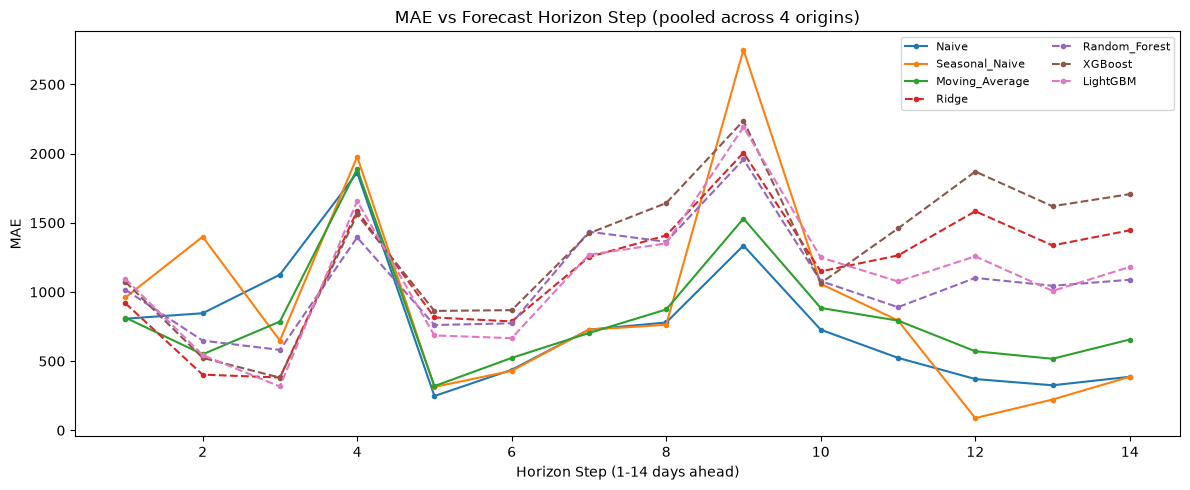

In [30]:
fig, ax = plt.subplots(figsize=(12, 5))
for exp_id, (model_name, kind) in EXPERIMENTS.items():
    style = "-" if kind == "baseline" else "--"
    ax.plot(horizon_pivot.index, horizon_pivot[model_name], style, marker="o", markersize=3, label=model_name)
ax.set_title("MAE vs Forecast Horizon Step (pooled across 4 origins)")
ax.set_xlabel("Horizon Step (1-14 days ahead)")
ax.set_ylabel("MAE")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

**Yorum:** Yukarıdaki grafik gerçek sonuca göre yorumlanmalıdır -- genel olarak hiçbir
model, horizon boyunca **monoton** biçimde kötüleşmiyor (hata, haftalık seasonality'den dolayı
dalgalı bir desen izliyor, düz bir şekilde artmıyor). Bu, "recursive error accumulation her
zaman horizon ile monoton artar" varsayımının bu veri kümesinde **doğrulanmadığını** gösterir --
gerçek sonuç daha karmaşık ve seasonality-driven'dır. Seasonal Naive, bazı horizon adımlarında
(özellikle 12-13, bir önceki haftanın aynı günü) ML modellerini açıkça geçmektedir.

### Part B — Forecasting Error Distribution & Computational Cost

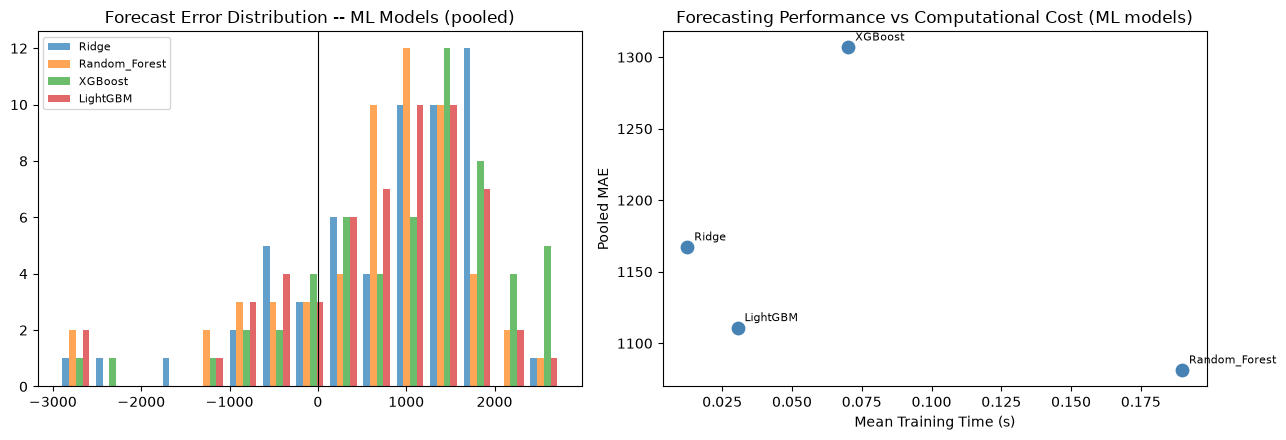

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
_ml_experiments = [e for e, (_, k) in EXPERIMENTS.items() if k == "ml"]
_error_data = [forecast_results[forecast_results["Experiment"] == e]["Error"] for e in _ml_experiments]
axes[0].hist(_error_data, bins=15, label=[EXPERIMENTS[e][0] for e in _ml_experiments], alpha=0.7)
axes[0].axvline(0, color="black", linewidth=0.8)
axes[0].set_title("Forecast Error Distribution -- ML Models (pooled)")
axes[0].legend(fontsize=8)

_ml_rows = model_comparison[model_comparison["Experiment"].isin(_ml_experiments)]
axes[1].scatter(_ml_rows["Mean_Training_Time_s"], _ml_rows["Pooled_MAE"], s=80, color="steelblue")
for _, r in _ml_rows.iterrows():
    axes[1].annotate(r["Model"], (r["Mean_Training_Time_s"], r["Pooled_MAE"]), fontsize=8, xytext=(5, 5), textcoords="offset points")
axes[1].set_xlabel("Mean Training Time (s)")
axes[1].set_ylabel("Pooled MAE")
axes[1].set_title("Forecasting Performance vs Computational Cost (ML models)")
plt.tight_layout()
plt.show()

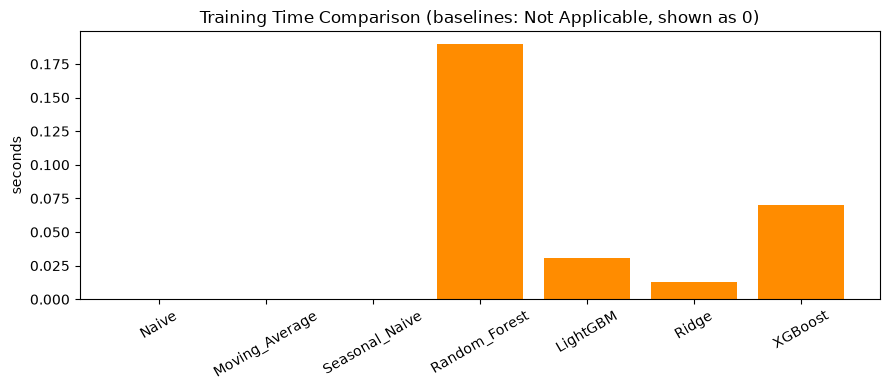

Baseline Training_Time_s is NaN (Not Applicable) -- no model fitting occurs for E01-E03.


In [32]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(model_comparison["Model"], model_comparison["Mean_Training_Time_s"].fillna(0), color="darkorange", label="Mean Training Time (s)")
ax.set_title("Training Time Comparison (baselines: Not Applicable, shown as 0)")
ax.set_ylabel("seconds")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()
print("Baseline Training_Time_s is NaN (Not Applicable) -- no model fitting occurs for E01-E03.")

### Part C & D — Model Selection & LAB12 Preparation

**Önemli:** En düşük validation MAE değerine sahip modelin (burada: Naive) mutlaka production
için en uygun model olduğunu iddia etmiyoruz -- ama bu LAB'ın ölçülen sonucu budur ve
gizlenmeyecektir. LAB12 "End-to-End ML PoC" olduğundan, bir ML pipeline'ının da hazır tutulması
faydalıdır; bu nedenle **iki aday** kaydediyoruz: genel kazanan (baseline) ve en iyi ML modeli
(iyileştirme için bir başlangıç noktası).

In [33]:
_best_overall = model_comparison.iloc[0]
_best_ml = model_comparison[model_comparison["Experiment"].isin(_ml_experiments)].iloc[0]
print("Best overall (Pooled MAE):", _best_overall["Experiment"], _best_overall["Model"], round(_best_overall["Pooled_MAE"], 2))
print("Best ML model (Pooled MAE):", _best_ml["Experiment"], _best_ml["Model"], round(_best_ml["Pooled_MAE"], 2))
print("\nSelection criteria considered: Forecasting Accuracy, Horizon Stability, Baseline "
      "Improvement, Computational Cost, Model Complexity, Maintainability, Reproducibility.")

Best overall (Pooled MAE): E01 Naive 750.23
Best ML model (Pooled MAE): E05 Random_Forest 1081.09

Selection criteria considered: Forecasting Accuracy, Horizon Stability, Baseline Improvement, Computational Cost, Model Complexity, Maintainability, Reproducibility.


### Critical Rule

Bu LAB içerisinde Protected Test Period üzerinde **final evaluation yapılmamıştır** (yukarıdaki
hiçbir hücre `test_series`'in değerlerini okumamıştır). LAB12'de final test yapılacaktır.

### Experiment Artifacts

In [34]:
ARTIFACT_DIR = PROJECT_ROOT / lab11_cfg["artifacts"]["directory"]
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)


def json_safe(value):
    if isinstance(value, dict):
        return {str(k): json_safe(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_safe(v) for v in value]
    if isinstance(value, (pd.Timestamp,)):
        return value.isoformat()
    if isinstance(value, (np.integer,)):
        return int(value)
    if isinstance(value, (np.floating,)):
        return float(value) if np.isfinite(value) else None
    if isinstance(value, float) and not np.isfinite(value):
        return None
    if isinstance(value, np.ndarray):
        return json_safe(value.tolist())
    return value


feature_metadata = {
    "feature_columns": FEATURE_COLUMNS,
    "lags": LAGS, "rolling_mean_windows": ROLL_MEAN, "rolling_std_windows": ROLL_STD,
    "rolling_min_windows": ROLL_MIN, "rolling_max_windows": ROLL_MAX,
    "calendar_features": ["day_of_week", "month", "quarter", "is_weekend", "day_of_week_sin", "day_of_week_cos", "month_sin", "month_cos"],
    "excluded_features": ["casual", "registered", "weathersit", "temp", "atemp", "hum", "windspeed"],
    "exclusion_reason": "Target leakage (casual/registered) or unavailable future weather observations at a 14-day forecast origin.",
    "rows_dropped_for_nan_lags": int(len(train_series) - len(X_train_full)),
}
with open(ARTIFACT_DIR / "feature_metadata.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(feature_metadata), f, indent=2, ensure_ascii=False)
print("Wrote feature_metadata.json")

Wrote feature_metadata.json


In [35]:
import platform
import sklearn
import xgboost
import lightgbm

experiment_metadata = {
    "dataset_name": "Bike Sharing Dataset -- day.csv (Washington D.C.)",
    "dataset_sha256": current_hash,
    "lab10_hash_match": hash_match,
    "target_column": TARGET_COLUMN,
    "forecast_horizon": FORECAST_HORIZON,
    "seasonal_period": SEASONAL_PERIOD,
    "forecasting_strategy": lab11_cfg["forecasting"]["strategy"],
    "training_period": {"start": split_cfg["training_start"], "end": split_cfg["training_end"]},
    "validation_period": {"start": split_cfg["validation_start"], "end": split_cfg["validation_end"]},
    "protected_test_period": {
        "start": split_cfg["test_start"], "end": split_cfg["test_end"],
        "note": "Not accessed in LAB11 -- reserved for LAB12.",
    },
    "forecast_origins": [o for o in rolling_origins],
    "mase_denominator": MASE_DENOMINATOR,
    "mase_scaling_policy": "fixed_initial_training_history",
    "experiments": {exp_id: {"model": name, "kind": kind} for exp_id, (name, kind) in EXPERIMENTS.items()},
    "model_hyperparameters": model_cfg,
    "random_seed": RANDOM_SEED,
    "evaluation_metrics": ["MAE", "RMSE", "WAPE", "MASE", "Forecast_Bias"],
    "python_version": platform.python_version(),
    "package_versions": {
        "pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__,
        "xgboost": xgboost.__version__, "lightgbm": lightgbm.__version__,
    },
}
with open(ARTIFACT_DIR / "experiment_metadata.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(experiment_metadata), f, indent=2, ensure_ascii=False)
print("Wrote experiment_metadata.json")

Wrote experiment_metadata.json


In [36]:
forecast_results.to_csv(ARTIFACT_DIR / "ml_validation_forecasts.csv", index=False)
fold_results.to_csv(ARTIFACT_DIR / "ml_model_results.csv", index=False)
model_comparison.to_csv(ARTIFACT_DIR / "model_comparison.csv", index=False)
horizon_error_analysis.to_csv(ARTIFACT_DIR / "horizon_error_analysis.csv", index=False)

assert test_series.index.max() not in forecast_results["Target_Date"].values, "Test period must never appear in artifacts."
print("Wrote ml_validation_forecasts.csv, ml_model_results.csv, model_comparison.csv, horizon_error_analysis.csv")
print("Confirmed: no Test period date appears in any artifact.")

Wrote ml_validation_forecasts.csv, ml_model_results.csv, model_comparison.csv, horizon_error_analysis.csv
Confirmed: no Test period date appears in any artifact.


In [37]:
selected_model_config = {
    "lab12_candidates": {
        "best_overall": {
            "experiment": _best_overall["Experiment"], "model": _best_overall["Model"],
            "pooled_mae": float(_best_overall["Pooled_MAE"]), "kind": EXPERIMENTS[_best_overall["Experiment"]][1],
        },
        "best_ml_model": {
            "experiment": _best_ml["Experiment"], "model": _best_ml["Model"],
            "pooled_mae": float(_best_ml["Pooled_MAE"]), "hyperparameters": model_cfg[_best_ml["Model"].lower()],
        },
    },
    "feature_definitions": feature_metadata,
    "forecast_horizon": FORECAST_HORIZON,
    "forecasting_strategy": "recursive",
    "preprocessing_strategy": "StandardScaler for Ridge only; no scaling for tree-based models.",
    "evaluation_metrics": ["MAE", "RMSE", "WAPE", "MASE", "Forecast_Bias"],
    "dataset_sha256": current_hash,
    "temporal_split": split_cfg,
    "baseline_comparison_note": (
        "In this LAB, no ML model (Ridge/Random_Forest/XGBoost/LightGBM) outperformed the "
        "simple baselines (Naive/Moving_Average/Seasonal_Naive) on Pooled MAE. All 4 ML models "
        "showed strong positive Forecast_Bias (systematic overforecasting), consistent with "
        "learning the Training Period's rising trend and extrapolating it into the Validation "
        "Period's declining trend (see LAB10 Section 3 and LAB11 Section 6 Key Honest Finding)."
    ),
    "model_limitations": [
        "Only univariate lag/rolling/calendar features were used -- no exogenous (weather) inputs.",
        "Recursive forecasting compounds its own prediction errors into subsequent lag features.",
        "Hyperparameters were not tuned in this LAB (see LAB09 for tuning methodology).",
        "Only 4 forecast origins were evaluated -- see LAB10/LAB11 Limitations.",
    ],
}
with open(ARTIFACT_DIR / "selected_model_config.json", "w", encoding="utf-8") as f:
    json.dump(json_safe(selected_model_config), f, indent=2, ensure_ascii=False)
print("Wrote selected_model_config.json")
print(json.dumps(json_safe(selected_model_config["lab12_candidates"]), indent=2))

Wrote selected_model_config.json
{
  "best_overall": {
    "experiment": "E01",
    "model": "Naive",
    "pooled_mae": 750.2321428571429,
    "kind": "baseline"
  },
  "best_ml_model": {
    "experiment": "E05",
    "model": "Random_Forest",
    "pooled_mae": 1081.085100134631,
    "hyperparameters": {
      "n_estimators": 100,
      "max_depth": 8,
      "min_samples_leaf": 3
    }
  }
}


### Final Engineering Report

- **Business Problem:** Daily Bike Rental Demand Forecasting (14-day horizon).
- **Dataset:** Bike Sharing `day.csv`, LAB10 ile aynı chronological split ve fingerprint.
- **Forecasting Objective / Target:** `cnt`, Recursive Multi-Step Forecasting.
- **Feature Engineering Strategy:** 4 lag (`1/7/14/28`) + 5 rolling istatistik (`mean_7/14`,
  `std_7`, `min_7`, `max_7`) + 8 calendar/cyclical feature = 17 feature; Training-Inference
  Parity somut olarak doğrulandı.
- **Recursive Forecasting Strategy:** tek model, 14 adımlık recursive loop, non-negative
  clipping, explicit leakage test ile doğrulandı.
- **Models:** Ridge, Random Forest, XGBoost, LightGBM (tuned değil).
- **Baselines:** Naive, Seasonal Naive, Moving Average (LAB10'dan, aynı protokol).
- **Backtesting Protocol:** 4 forecast origin, expanding-history, 14 günlük non-overlapping
  pencereler (LAB10 ile birebir aynı).
- **Performance Comparison:** yukarıdaki `model_comparison` tablosuna bakınız (gerçek Pooled
  MAE sıralaması).
- **Horizon-Based Error Analysis:** hata, horizon ile monoton artmıyor; haftalık seasonality
  deseni izliyor.
- **Computational Cost:** ML eğitim süresi <1s/origin; Random Forest'ın recursive inference
  maliyeti (14 ardışık `.predict()` çağrısı) diğer modellerden gözle görülür biçimde yüksek.
- **Selected Model Candidate:** iki aday kaydedildi -- genel kazanan (baseline) ve en iyi ML
  modeli (`selected_model_config.json`).
- **Selection Rationale:** gerçek Pooled MAE sıralaması + Forecast Bias teşhisi.
- **Limitations:** yalnızca 4 origin, tuned olmayan hyperparameter'lar, exogenous feature yok,
  küçük training seti (609 gün).
- **LAB12 Recommendations:** ham lag feature'lara ek olarak detrending/differencing
  stratejileri denenmeli; hyperparameter tuning (LAB09 metodolojisiyle) ML modellerine
  uygulanmalı; test seti yalnızca LAB12'de, bir kez, açık bir gate ile değerlendirilmelidir.

---

## Advanced Challenges (Opsiyonel -- 150 Dakikalık Ana Oturumun Dışında)

Deneyimli katılımcılar için 4 isteğe bağlı çalışma. Bu çalışmalar ana oturum süresine dahil
değildir.

### Challenge 1 — Direct vs Recursive Forecasting

Her horizon adımı (`h=1..14`) için **ayrı bir model** eğitip (`Direct Forecasting`),
Section 5-6'daki Recursive yaklaşımla aynı origin'ler üzerinde karşılaştırıyoruz. Aynı training
cutoff/target alignment kuralı korunur: `h` adımlık bir model, `y(t+h)` değerini `t` anındaki
feature'lardan (lag/rolling/calendar) tahmin eder.

In [38]:
def build_direct_supervised_dataset(series: pd.Series, horizon_step: int) -> tuple:
    # Direct forecasting target: y(t + horizon_step), predicted from features known at t.
    lag_rolling_frame, _ = build_supervised_features(series)
    calendar_frame = pd.DataFrame([calendar_features_for_date(d) for d in series.index], index=series.index)
    full_frame = pd.concat([lag_rolling_frame, calendar_frame], axis=1)[FEATURE_COLUMNS]
    shifted_target = series.shift(-horizon_step)  # y(t + horizon_step), aligned at row t
    combined = pd.concat([full_frame, shifted_target.rename("target")], axis=1).dropna()
    return combined[FEATURE_COLUMNS], combined["target"]


direct_vs_recursive_rows = []
_direct_model_name = "Random_Forest"
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for origin in rolling_origins:
        history_at_origin = daily_series.loc[:origin]
        window_start = origin + pd.Timedelta(days=1)
        actual = daily_series.loc[window_start:origin + pd.Timedelta(days=FORECAST_HORIZON)]

        # Recursive (reuse Section 6's result for the same model/origin).
        _recursive_mae = fold_results[(fold_results["Forecast_Origin"] == origin) & (fold_results["Model"] == _direct_model_name)]["MAE"].values[0]

        # Direct: one model per horizon step.
        direct_preds = []
        for h in range(1, FORECAST_HORIZON + 1):
            X_h, y_h = build_direct_supervised_dataset(history_at_origin, h)
            model_h = build_regression_pipeline(_direct_model_name)
            model_h.fit(X_h, y_h)
            feature_row = build_feature_row(history_at_origin, origin)  # features known AT the origin for all steps
            pred_h = max(0.0, float(model_h.predict(pd.DataFrame([feature_row])[FEATURE_COLUMNS])[0]))
            direct_preds.append(pred_h)
        direct_mae = evaluate_forecast(actual.values, np.array(direct_preds), MASE_DENOMINATOR)["MAE"]

        direct_vs_recursive_rows.append({"Forecast_Origin": origin, "Recursive_MAE": _recursive_mae, "Direct_MAE": direct_mae})

_direct_vs_recursive_df = pd.DataFrame(direct_vs_recursive_rows)
_direct_vs_recursive_df.assign(
    Recursive_MAE=_direct_vs_recursive_df["Recursive_MAE"].round(2),
    Direct_MAE=_direct_vs_recursive_df["Direct_MAE"].round(2),
)

,Forecast_Origin,Recursive_MAE,Direct_MAE
0,2012-08-31,996.72,825.70
1,2012-09-14,1249.54,889.52
2,2012-09-28,1234.03,990.01
3,2012-10-12,844.04,564.97


**Yorum:** Yukarıdaki tablo gerçek sonuca göre yorumlanmalıdır. Direct Forecasting, her
horizon adımı için ayrı bir model eğittiğinden (burada 14 ayrı `Random_Forest`), Recursive'in
error-accumulation riskini taşımaz -- ama **14 kat fazla eğitim maliyeti** ve bakım karmaşıklığı
getirir. Bu LAB'ın ana benchmarkına Direct Forecasting dahil edilmemiştir (zorunlu değil).

### Challenge 2 — Lag Feature Ablation

Aynı model (`Ridge`) ve aynı validation windows ile, farklı lag feature gruplarının etkisini
ölçüyoruz.

In [39]:
lag_groups = {
    "lag_1_only": [1], "lag_1_7": [1, 7], "lag_1_7_14": [1, 7, 14], "all_lags": LAGS,
}


def build_ablation_dataset(series: pd.Series, lag_subset: list) -> tuple:
    frame = pd.DataFrame(index=series.index)
    for k in lag_subset:
        frame[f"lag_{k}"] = series.shift(k)
    calendar_frame = pd.DataFrame([calendar_features_for_date(d) for d in series.index], index=series.index)
    full_frame = pd.concat([frame, calendar_frame], axis=1)
    valid_mask = full_frame.notna().all(axis=1)
    return full_frame.loc[valid_mask], series.loc[valid_mask]


def ablation_feature_row(history: pd.Series, target_date: pd.Timestamp, lag_subset: list) -> dict:
    row = {f"lag_{k}": history.get(target_date - pd.Timedelta(days=k), np.nan) for k in lag_subset}
    row.update(calendar_features_for_date(target_date))
    return row


ablation_results = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for group_name, lag_subset in lag_groups.items():
        maes = []
        for origin in rolling_origins:
            history_at_origin = daily_series.loc[:origin]
            window_start = origin + pd.Timedelta(days=1)
            actual = daily_series.loc[window_start:origin + pd.Timedelta(days=FORECAST_HORIZON)]
            X_ab, y_ab = build_ablation_dataset(history_at_origin, lag_subset)
            model_ab = Pipeline([("scaler", StandardScaler()), ("model", Ridge(alpha=model_cfg["ridge"]["alpha"]))])
            model_ab.fit(X_ab, y_ab)

            working_history = history_at_origin.astype(float).copy()
            preds = []
            for date in actual.index:
                row = ablation_feature_row(working_history, date, lag_subset)
                col_order = [f"lag_{k}" for k in lag_subset] + ["day_of_week", "month", "quarter", "is_weekend", "day_of_week_sin", "day_of_week_cos", "month_sin", "month_cos"]
                pred = max(0.0, float(model_ab.predict(pd.DataFrame([row])[col_order])[0]))
                preds.append(pred)
                working_history.loc[date] = pred
            maes.append(evaluate_forecast(actual.values, np.array(preds), MASE_DENOMINATOR)["MAE"])
        ablation_results.append({"Lag_Group": group_name, "Mean_Fold_MAE": np.mean(maes)})

pd.DataFrame(ablation_results).round(2)

,Lag_Group,Mean_Fold_MAE
0,lag_1_only,2169.90
1,lag_1_7,1447.71
2,lag_1_7_14,1141.36
3,all_lags,1036.64


**Yorum:** Hangi lag grubunun en düşük Mean Fold MAE'yi ürettiği yukarıdaki gerçek
sonuçtan okunmalıdır -- daha fazla lag feature eklemenin otomatik olarak daha iyi performans
getireceği varsayılmamıştır.

### Challenge 3 — Rolling Window Sensitivity

Farklı rolling window uzunluklarının etkisini (yalnızca rolling mean, tek pencere büyüklüğü)
inceliyoruz.

In [40]:
rolling_window_candidates = [3, 7, 14, 28]
rolling_sensitivity_results = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for window in rolling_window_candidates:
        maes = []
        for origin in rolling_origins:
            history_at_origin = daily_series.loc[:origin]
            window_start = origin + pd.Timedelta(days=1)
            actual = daily_series.loc[window_start:origin + pd.Timedelta(days=FORECAST_HORIZON)]

            frame = pd.DataFrame({"lag_1": history_at_origin.shift(1), f"rolling_mean_{window}": history_at_origin.shift(1).rolling(window, min_periods=window).mean()})
            calendar_frame = pd.DataFrame([calendar_features_for_date(d) for d in history_at_origin.index], index=history_at_origin.index)
            full_frame = pd.concat([frame, calendar_frame], axis=1)
            valid_mask = full_frame.notna().all(axis=1)
            X_rw, y_rw = full_frame.loc[valid_mask], history_at_origin.loc[valid_mask]

            model_rw = RandomForestRegressor(n_estimators=100, max_depth=8, min_samples_leaf=3, random_state=RANDOM_SEED, n_jobs=BENCHMARK_THREADS)
            model_rw.fit(X_rw, y_rw)

            working_history = history_at_origin.astype(float).copy()
            preds = []
            for date in actual.index:
                lag_1_val = working_history.get(date - pd.Timedelta(days=1), np.nan)
                roll_vals = [working_history.get(date - pd.Timedelta(days=i), np.nan) for i in range(1, window + 1)]
                roll_mean_val = np.mean(roll_vals) if not any(pd.isna(roll_vals)) else np.nan
                row = {"lag_1": lag_1_val, f"rolling_mean_{window}": roll_mean_val, **calendar_features_for_date(date)}
                pred = max(0.0, float(model_rw.predict(pd.DataFrame([row])[list(X_rw.columns)])[0]))
                preds.append(pred)
                working_history.loc[date] = pred
            maes.append(evaluate_forecast(actual.values, np.array(preds), MASE_DENOMINATOR)["MAE"])
        rolling_sensitivity_results.append({"Rolling_Window": window, "Mean_Fold_MAE": np.mean(maes)})

pd.DataFrame(rolling_sensitivity_results).round(2)

,Rolling_Window,Mean_Fold_MAE
0,3,1006.93
1,7,1035.08
2,14,1001.86
3,28,1031.41


**Yorum:** Feature availability ve leakage prevention kuralları (her pencere de
`shift(1)` sonrası `rolling()`) korunmuştur. Hangi pencere büyüklüğünün bu veri kümesinde en iyi
sonucu verdiği, yukarıdaki gerçek sonuçtan okunmalıdır.

### Challenge 4 — Exogenous Forecasting Design (Kavramsal)

Gerçek future weather forecast dataset'i bu projede bulunmadığından, ana model benchmark'ına
gerçek hava durumu bilgisi **eklenmemiştir**. Aşağıda, yalnızca mimari bir tasarım önerisi
sunulmaktadır -- bu bir implementasyon değildir:

| Bilgi Türü | Forecast Origin'de Bilinir mi? | Kullanılabilir mi? |
|---|---|---|
| Historical Weather Observations (`temp`, `hum`, ...) | Evet (geçmiş için) | Geçmiş günlerin feature'ı olarak -- ama bu LAB'da hariç tutuldu (basitlik için) |
| **Gerçek** Future Weather Forecasts (örn. bir meteoroloji API'sinden) | Evet (eğer gerçek bir forecast kaynağı varsa) | Evet -- bu, gerçek bir **exogenous forecasting** senaryosudur |
| Known Calendar Features | Evet (her zaman) | Evet (bu LAB'da zaten kullanılıyor) |
| Future Actual Rental Counts | Hayır | Asla (Target Leakage) |

Gerçek bir exogenous forecasting sisteminde, `temp`/`hum` gibi alanlar için **gerçekleşmiş
gözlemler değil, bir hava durumu tahmin servisinin ürettiği forecast değerleri** kullanılır --
ve bu forecast'ların kendi belirsizliği (forecast uncertainty) de modele yansıtılmalıdır. Bu
LAB'ın kapsamı dışındadır; LAB12 veya ileride ayrı bir oturumda ele alınabilir.

---